In [1]:
# ติดตั้งแพ็กเกจเมื่อรันใน repo — บน Kaggle มี pandas/matplotlib พร้อมอยู่แล้ว
from pathlib import Path

if Path("requirements-offline.txt").exists():
    get_ipython().run_line_magic(
        "pip", "install -r requirements-offline.txt --quiet")
else:
    print("ข้ามการติดตั้ง — ใช้แพ็กเกจที่มีใน environment (เช่น Kaggle)")

/Users/utarn/projects/datascience-metrology/.check-env/bin/python: No module named pip


Note: you may need to restart the kernel to use updated packages.


# Module M7 — ทำงานอัตโนมัติ

|  |  |
|---|---|
| **เวลา** | Day 2, 14:00–14:45 (45 นาที) · Offline (CPU) |
| **ข้อมูล** | PM2.5 รายวัน ปี 2568 (15 สถานี) |

**เมื่อจบโมดูลนี้ ผู้เรียนจะ...**

- เปลี่ยนงาน "ทำมือซ้ำ ๆ" ให้เป็นสคริปต์ที่รันครั้งเดียวจบ
- วนผลิตรายงานหลายไฟล์อัตโนมัติ (หนึ่งกลุ่ม = หนึ่งไฟล์)
- รู้ขอบเขต: อะไรควรอัตโนมัติ อะไรต้องทำมือ

**ข้อมูลที่ใช้ (citation):**

> กรมควบคุมมลพิษ (2568). *ข้อมูลคุณภาพอากาศ PM2.5 รายวัน 15 สถานี*,
> pcd.gdcatalog.go.th (Open Data Common) — extract 15 สถานีจากไฟล์เต็ม
> (กทม. 12 + เชียงใหม่ 2 + หาดใหญ่ 1)

## 1. งานซ้ำ ๆ คืองานของคอมพิวเตอร์

สถานการณ์: หัวหน้าขอ "สรุป PM2.5 รายเดือน แยกตามสถานี 15 สถานี ส่งพรุ่งนี้"

ทำมือ = กรอง 1 สถานี → groupby → คัดลอกผลลง Excel → เปลี่ยนชื่อสถานี
→ ทำซ้ำอีก 14 ครั้ง (~2 ชั่วโมง และพลาดคนละจุดแน่นอน)

เราจะทำ**เทมเพลตให้ดี 1 ครั้ง** แล้ววนซ้ำให้คอมพิวเตอร์จบในไม่กี่วินาที —
นี่คือทั้งหมดของ "automation" ในระดับที่ใช้ได้จริง

In [2]:
import pandas as pd
from pathlib import Path

import os


def data_root() -> Path:
    """หาโฟลเดอร์ datasets/ — ใช้ได้ทั้ง repo local, venv และ Kaggle.

    ลำดับการค้นหา:
    1. environment variable COURSE_DATA_ROOT (ชี้ตรงไปที่โฟลเดอร์ datasets)
    2. โฟลเดอร์ datasets/ ที่อยู่ระดับเดียวกับโน้ตบุ๊กหรือแม่ขึ้นไป (repo local)
    3. /kaggle/input — ทั้งกรณีอัปโหลด datasets/ ทั้งโฟลเดอร์
       หรืออัปโหลดแต่ละชุดแยกกัน (ชื่อโฟลเดอร์ต้องตรงกับใน datasets/)
    """
    env = os.environ.get("COURSE_DATA_ROOT")
    if env:
        return Path(env)
    for p in (Path.cwd(), *Path.cwd().parents):
        if (p / "datasets").is_dir():
            return p / "datasets"
    kaggle = Path("/kaggle/input")
    if kaggle.is_dir():
        hits = sorted(kaggle.glob("**/datasets"))
        if hits:
            return hits[0]
        return kaggle
    raise SystemExit(
        "ไม่พบโฟลเดอร์ datasets/ — ตั้ง COURSE_DATA_ROOT "
        "หรือวาง datasets/ ไว้ข้างโน้ตบุ๊ก")

DATA = data_root()

pm25 = pd.read_csv(DATA / "pcd_pm25_2025"
                   / "pm25_daily_2025_15stations.csv")
pm25["date"] = pd.to_datetime(pm25["observation_date"])
# .dt = เข้าถึงส่วนวันที่ของคอลัมน์ datetime (เหมือน .str ของข้อความ)
pm25["month"] = pm25["date"].dt.month
print(f"{len(pm25):,} แถว · {pm25['station_code'].nunique()} สถานี")

5,475 แถว · 15 สถานี


In [3]:
# เทมเพลตทำมือ — สถานีเดียว 02T (ธนบุรี)
one = pm25[pm25["station_code"] == "02T"]
summary = one.groupby("month").agg(
    mean_pm25=("measured_value", "mean"),
    max_pm25=("measured_value", "max"),
    n_days=("measured_value", "size"),
)
summary.round(1).head(4)

,mean_pm25,max_pm25,n_days
month,,,
1,51.1,88.9,31
2,39.1,71.1,28
3,32.5,77.2,31
4,20.5,37.2,30


ตารางนี้ถูกต้อง — แต่ถ้าต้องทำอีก 14 สถานี วิธีเดียวที่ผิดคือ
"คัดลอกเซลล์นี้ 14 ครั้งแล้วแก้ชื่อสถานี" — เปลี่ยนชื่อหลุดหนึ่งจุด
ผลลัพธ์เงียบ ๆ ผิดตั้งแต่ไฟล์ที่ 7 ไม่มีใครรู้

ทางที่ถูก: วนด้วย `for` เหนือกลุ่มที่ `groupby` แบ่งไว้ให้:

## ✏️ ลองเอง 1 — สรุปสถานีถัดไป

เทมเพลตเดิมใช้กับสถานีอื่นได้ทันที — ลองสร้างตารางสรุปรายเดือนแบบเดียวกันสำหรับสถานี `03T` แล้วพิมพ์จำนวนแถวของตารางสรุปพร้อม 4 แถวแรกออกมาดู

**คำใบ้:** เปลี่ยนแค่ค่าในเงื่อนไข `pm25[...]` เป็น `"03T"` ส่วน `groupby("month").agg(...)` ใช้ชุดเดิม พิมพ์จำนวนแถวในรูปแบบ `จำนวนแถว: <n>` แล้วจึงพิมพ์ตาราง


In [ ]:
# ลองเขียนโค้ดของคุณที่นี่
# พิมพ์จำนวนแถวของตารางสรุป (ควรได้ 12) แล้วพิมพ์ 4 แถวแรก


<div style="background-color:#e8f1fb; border-left:4px solid #2b6cb0; padding:10px 14px; border-radius:4px; color:#123d6b;">

**ผลลัพธ์ที่คาดหวัง**

<pre style="margin:8px 0 0 0; white-space:pre-wrap; color:#123d6b;">จำนวนแถว: 12
       mean_pm25  max_pm25  n_days
month                             
1           49.8      91.0      31
2           38.8      72.6      28
3           32.2      76.8      31
4           20.4      37.4      30</pre>

</div>

## 2. วนทุกสถานี — 15 รายงานในคำสั่งเดียว

`for code, group in pm25.groupby("station_code"):` ให้**ทั้งคู่**ทีละกลุ่ม —
`code` = ชื่อกลุ่ม (ใช้ตั้งชื่อไฟล์) · `group` = แถวของกลุ่มนั้นทั้งหมด:

In [4]:
outputs = Path("outputs")
outputs.mkdir(exist_ok=True)        # สร้างโฟลเดอร์ถ้ายังไม่มี

for code, group in pm25.groupby("station_code"):
    summary = group.groupby("month").agg(
        mean_pm25=("measured_value", "mean"),
        max_pm25=("measured_value", "max"),
        n_days=("measured_value", "size"),
    )
    summary.round(1).to_csv(outputs / f"station_{code}.csv")

print("จบ — ไฟล์ที่เขียนแล้ว:")
for path in sorted(outputs.glob("station_*.csv")):
    print(f"  {path.name}")

จบ — ไฟล์ที่เขียนแล้ว:
  station_02T.csv
  station_03T.csv
  station_05T.csv
  station_10T.csv
  station_11T.csv
  station_12T.csv
  station_35T.csv
  station_36T.csv
  station_44T.csv
  station_50T.csv
  station_52T.csv
  station_53T.csv
  station_54T.csv
  station_59T.csv
  station_61T.csv


เปิดโฟลเดอร์ `outputs/` ดู — 15 ไฟล์เกิดขึ้นในไม่กี่วินาที

ชิ้นส่วนทั้งหมดมาจากโมดูลก่อนหน้า: `for` (M1) · `f-string` ตั้งชื่อไฟล์ (M1) ·
`groupby().agg()` (M2) · ที่เพิ่มใหม่มีแค่ `.to_csv()` เขียนตารางลงไฟล์
(แบบเดียวกับ `.to_excel()` ของ M2)

**ประเด็นสำคัญ:** สคริปต์นี้รันซ้ำพรุ่งนี้กับข้อมูลเดือนใหม่ก็ยังถูก —
งานวิเคราะห์ที่**ทำซ้ำได้** (reproducible) ต่างจากงานทำมือที่พรุ่งนี้
มือสั่นแก้ผิดช่องเอง

## 3. อ่านกลับมารวม — ทางกลับของกระบวนการ

บางงานได้ข้อมูลมาเป็น "หนึ่งไฟล์ต่อหนึ่งเครื่อง/แผนก" — ทางกลับของที่เราเพิ่งทำ
`Path.glob("station_*.csv")` หาไฟล์ที่ตรงแพทเทิร์นทั้งหมด (`*` = ชื่ออะไรก็ได้)
แล้ว `pd.concat` (M2) รวมกลับ:

In [5]:
frames = []
for path in sorted(outputs.glob("station_*.csv")):
    one = pd.read_csv(path)
    one["station"] = path.stem.removeprefix("station_")
    frames.append(one)

combined = pd.concat(frames, ignore_index=True)
print(f"อ่านกลับได้ {len(frames)} ไฟล์ → {len(combined):,} แถว "
      f"× {combined.shape[1]} คอลัมน์")
combined.head(3)

อ่านกลับได้ 15 ไฟล์ → 180 แถว × 5 คอลัมน์


,month,mean_pm25,max_pm25,n_days,station
0,1,51.1,88.9,31,02T
1,2,39.1,71.1,28,02T
2,3,32.5,77.2,31,02T


`path.stem` = ชื่อไฟล์ไม่รวมนามสกุล · `.removeprefix("station_")`
ตัดคำนำหน้าทิ้ง — ทั้งคู่ทำให้เราเอา "ชื่อสถานี" ที่ฝังอยู่ในชื่อไฟล์
กลับเข้ามาเป็นคอลัมน์ได้

จบวงจร: ตารางใหญ่ → แตกเป็นไฟล์ → รวมกลับเป็นตารางใหญ่ —
คู่ของ `to_csv` / `glob` + `concat` คือสะพานสองทิศของงานไฟล์จริง

## ✏️ ลองเอง 2 — นับไฟล์และแถวที่รวมได้

จาก `frames` และ `combined` ที่เพิ่งสร้าง ลองรายงานว่าอ่านกลับมากี่ไฟล์ และรวมได้ทั้งหมดกี่แถว โดยให้ผลลัพธ์สั้น ๆเพียง 1–2 บรรทัด

**คำใบ้:** `len(frames)` คือจำนวนไฟล์ ส่วน `len(combined)` คือจำนวนแถวทั้งหมด — ประกอบเป็น f-string ในรูปแบบ `<จำนวนไฟล์> ไฟล์ · <จำนวนแถว> แถว` ตามที่เรียนมา


In [ ]:
# ลองเขียนโค้ดของคุณที่นี่
# พิมพ์จำนวนไฟล์ที่รวมได้ และจำนวนแถวรวมทั้งหมด (1–2 บรรทัด)


<div style="background-color:#e8f1fb; border-left:4px solid #2b6cb0; padding:10px 14px; border-radius:4px; color:#123d6b;">

**ผลลัพธ์ที่คาดหวัง**

<pre style="margin:8px 0 0 0; white-space:pre-wrap; color:#123d6b;">15 ไฟล์ · 180 แถว</pre>

</div>

## 4. กราฟอัตโนมัติ — แถมท้าย

รายงานไม่มีกราฟไม่ได้ — วนวาดภาพประจำสถานี (3 สถานีพอสำหรับตัวอย่าง)
ด้วยเครื่องมือเดิมทั้งหมด รวม `savefig` จาก M4:

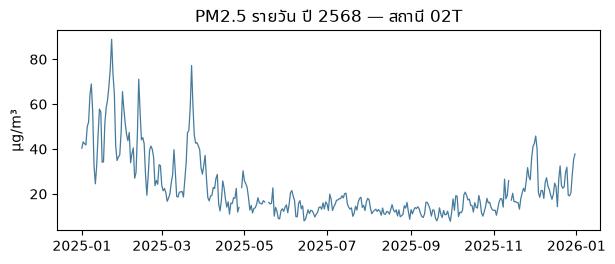

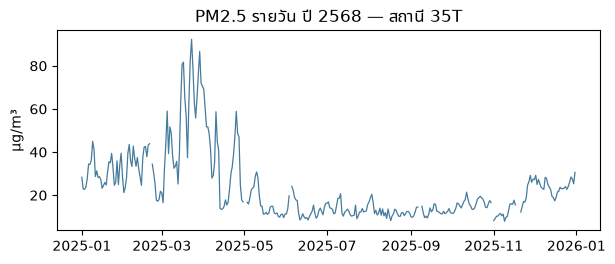

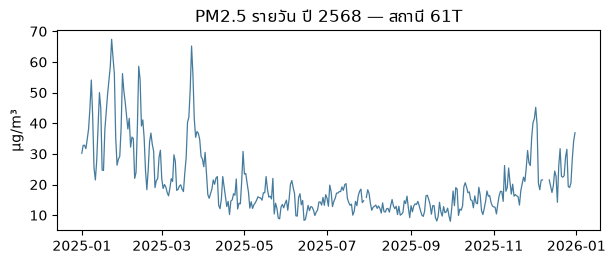

In [6]:
import matplotlib.pyplot as plt  # noqa: E402

plt.rcParams["font.family"] = [
    "DejaVu Sans", "Noto Sans Thai", "Leelawadee UI", "Tahoma",
]

for code in ["02T", "35T", "61T"]:
    one = pm25[pm25["station_code"] == code]
    fig, ax = plt.subplots(figsize=(7, 2.6))
    ax.plot(one["date"], one["measured_value"], color="#457b9d",
            lw=0.9)
    ax.set_title(f"PM2.5 รายวัน ปี 2568 — สถานี {code}")
    ax.set_ylabel("µg/m³")
    plt.savefig(outputs / f"chart_{code}.png", dpi=120,
                bbox_inches="tight")
    plt.show()

### อะไรควรอัตโนมัติ — อะไรทำมือดีกว่า

| ทำมือ | อัตโนมัติ |
|---|---|
| เลือกคำถามที่จะตอบ | กรอง/รวม/สรุปตามกฎที่ชัดเจน |
| ตัดสินใจว่าค่าแปลก = พลาดหรือจริง | ผลิตรายงาน/กราฟชุดเดิมซ้ำ |
| เขียนบทสรุปแปลผล | อัปเดตตัวเลขเมื่อข้อมูลมาใหม่ |

กฎนิ้วโป้ง: **งานที่ทำครั้งที่ 3 ด้วยขั้นตอนเดิม — เริ่มเขียนสคริปต์**

## 5. สรุป

- `for` เหนือ `groupby` = รายงานหลายไฟล์ · `to_csv` ออก · `glob` + `concat` กลับ
- automation ไม่ใช่เวทมนตร์ — คือเทมเพลตที่ดี + ลูปที่ซื่อสัตย์ต่อกฎ
- สิ่งที่ซื้อได้คือเวลา — สิ่งที่ได้ฟรีคือความถูกต้องที่ไม่ขึ้นกับความเหนื่อย

**ต่อไป — แบบฝึกปิดท้าย (reproduce a figure):** ย้อนไปสร้างกราฟหนึ่งภาพของคอร์ส
ขึ้นมาใหม่ด้วยข้อมูลจริงใน `datasets/` — ทุกทักษะสองวันนี้ใช้ครบในงานเดียว
จบคอร์สด้วยสไลด์ What's next: Python + ข้อมูลสะอาด + แนวโน้ม = วัตถุดิบของ ML